In [1]:
import pandas as pd
from pathlib import Path
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


#carico e leggo i dati
def load_data():
    data_path = Path("data/employee_salary_regression.csv")
    if not data_path.is_file():
        print(f'Errore nel caricamento del file {data_path}')
        return None
    return pd.read_csv(data_path)

data  = load_data()

#info generali sul dataset
print(data.info())

#stampo le prime 5 righe
print("\n Prime 5 righe del dataset: \n")
print(data.head().to_string())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   employee_id        1000 non-null   object 
 1   age                1000 non-null   int64  
 2   years_experience   1000 non-null   int64  
 3   education_level    1000 non-null   object 
 4   job_role           1000 non-null   object 
 5   city_tier          1000 non-null   int64  
 6   performance_score  1000 non-null   float64
 7   num_skills         1000 non-null   int64  
 8   remote_work        1000 non-null   int64  
 9   annual_salary_usd  1000 non-null   float64
dtypes: float64(2), int64(5), object(3)
memory usage: 78.3+ KB
None

 Prime 5 righe del dataset: 

  employee_id  age  years_experience education_level           job_role  city_tier  performance_score  num_skills  remote_work  annual_salary_usd
0     EMP0001   29                 9          Master  Software Engineer  

In [2]:
print("\n Approfondimento 'education_level': \n")
print(data["education_level"].value_counts().to_string())

print("\n Approfondimento 'job_role': \n")
print(data["job_role"].value_counts().to_string())

print("\n Approfondimento 'city_tier': \n")
print(data["city_tier"].value_counts().to_string())

print("\n Approfondimento 'remote_work': \n")
print(data["remote_work"].value_counts().to_string())


 Approfondimento 'education_level': 

education_level
Bachelor       258
PhD            256
Master         246
High School    240

 Approfondimento 'job_role': 

job_role
DevOps               190
Data Analyst         178
Product Manager      168
QA Engineer          165
Software Engineer    152
ML Engineer          147

 Approfondimento 'city_tier': 

city_tier
3    365
1    319
2    316

 Approfondimento 'remote_work': 

remote_work
0    512
1    488


In [3]:
#features selezionate (rimuovo employee_id)
attributes = [
    'age',
    'years_experience',
    'education_level',
    'job_role',
    'city_tier',
    'performance_score',
    'num_skills',
    'remote_work',
]
target='annual_salary_usd'

#Indice di person tra le features:
print(data[attributes+[target]].corr(numeric_only=True).to_string())


                        age  years_experience  city_tier  performance_score  num_skills  remote_work  annual_salary_usd
age                1.000000          0.992704  -0.050803          -0.015926    0.031856     0.003820           0.939521
years_experience   0.992704          1.000000  -0.051587          -0.011547    0.034281     0.004628           0.947786
city_tier         -0.050803         -0.051587   1.000000           0.035369   -0.010308    -0.032580          -0.240258
performance_score -0.015926         -0.011547   0.035369           1.000000   -0.002240    -0.000754           0.140946
num_skills         0.031856          0.034281  -0.010308          -0.002240    1.000000     0.022205           0.146429
remote_work        0.003820          0.004628  -0.032580          -0.000754    0.022205     1.000000           0.053142
annual_salary_usd  0.939521          0.947786  -0.240258           0.140946    0.146429     0.053142           1.000000


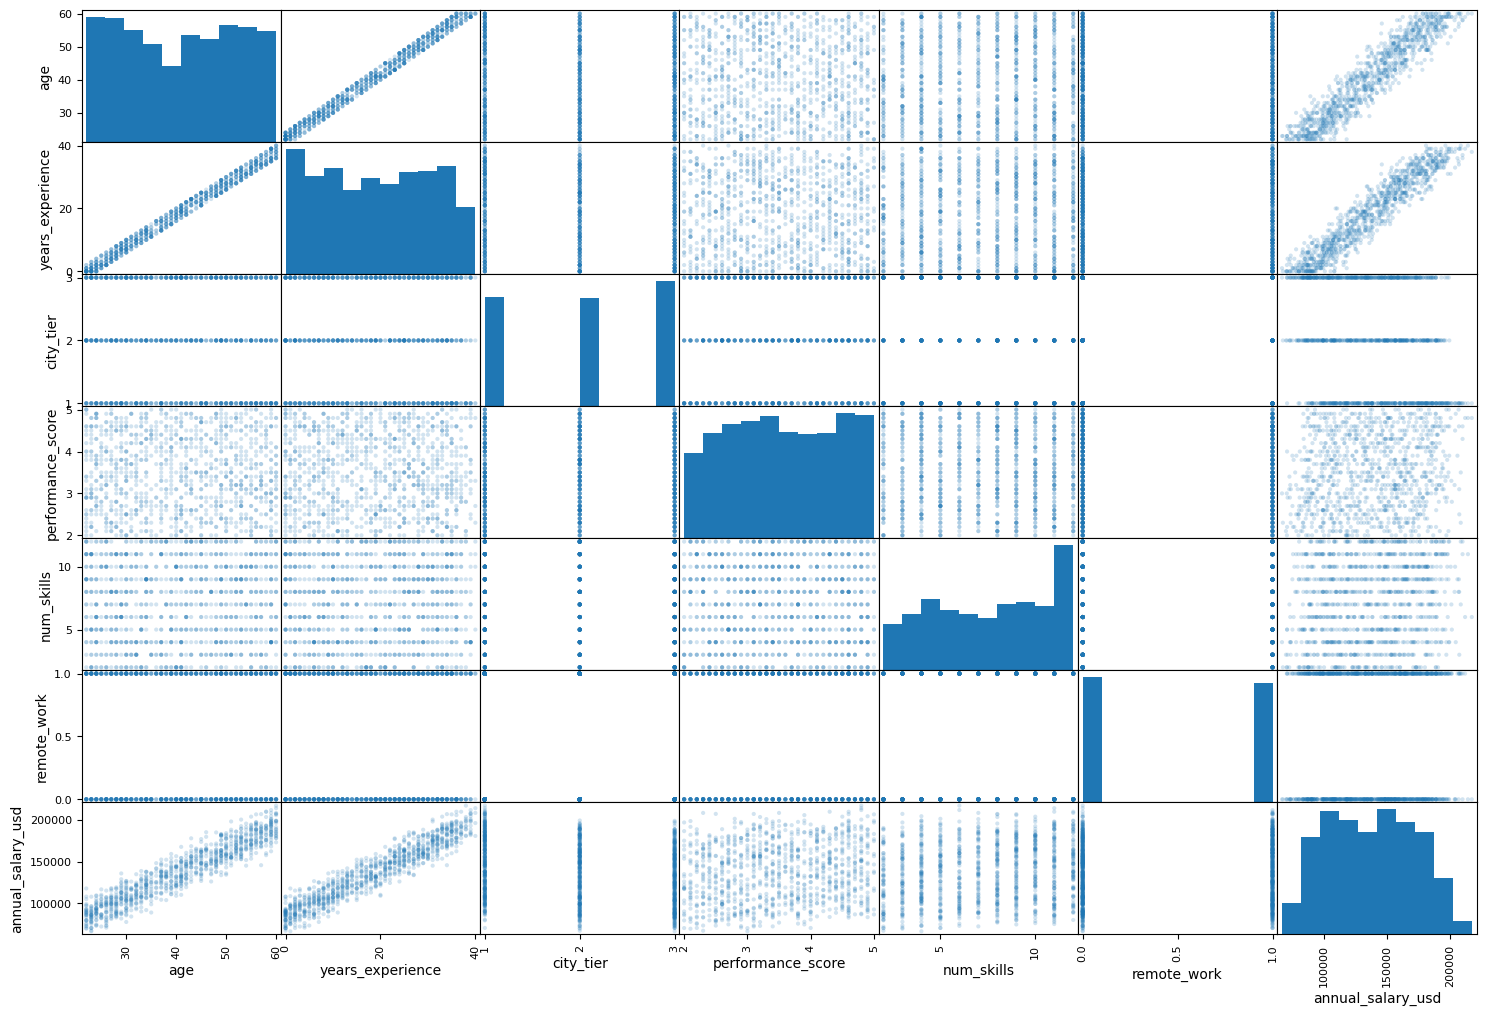

In [4]:
#scatter matrix per visualizzare la correlazione:
scatter_matrix(data[attributes+[target]], figsize=(18,12),alpha=0.2)
plt.show()

#multicollinearità (0.99) tra Età ed Esperienza
#age e years_experience hanno una correlazione positiva forte
# city_tier ha una correlazione negativa moderata
#num_skills e performance_score hanno una correlazione positiva ma debole
#annual_salary_usd non presenta outliers o heavy tails


MAE: $3490.76
MSE: $19243274.19
RMSE: $4386.72
R2: 0.9853


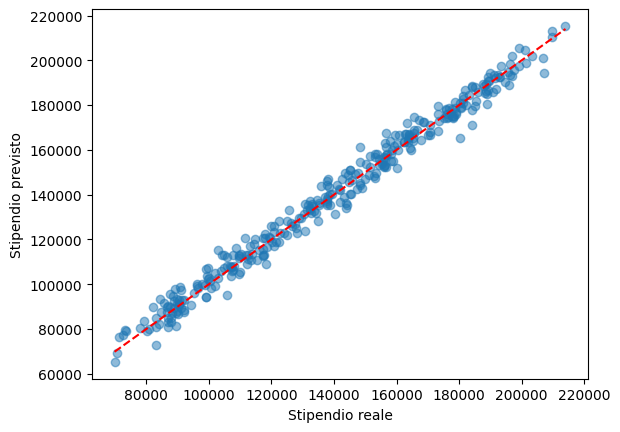

In [5]:
#rimuove age da attributes:
attributes.remove('age')
#divido i dati per il training e il testing:
X = data[attributes]
y = data[target].values

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.33,
    random_state = 42,
    shuffle = True
)

#definisco i vari tipi di features:
numeric_features = ['years_experience','performance_score','num_skills','city_tier'] 
categorical_features = ['education_level','job_role']
#remote_work già codificata come variabile binaria

preprocessor = ColumnTransformer(
    transformers=[
        ('numeriche', StandardScaler(), numeric_features),
        ('categoriche', OneHotEncoder(), categorical_features)
    ],
    remainder ='passthrough'
)

#trasformo i dati
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared =preprocessor.transform(X_test)

#utilizzo la linear regression:
model = LinearRegression()
model.fit(X_train_prepared,y_train)

y_pred = model.predict(X_test_prepared)

#calcolo dell'errore:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print(f"MAE: ${mae:.2f}")
print(f"MSE: ${mse:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"R2: {r2:.4f}")

#costruisco il grafico
plt.scatter(y_test,y_pred,alpha=0.5)
plt.xlabel("Stipendio reale")
plt.ylabel("Stipendio previsto")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         "r--")


plt.show()

In [6]:
#rete neurale

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#scalo le y:
y_scaled = StandardScaler()
y_train_scaled= y_scaled.fit_transform(y_train.reshape(-1,1))
y_test_scaled= y_scaled.transform(y_test.reshape(-1,1))

#converto le X già preparate in tensori:
X_train_tensor = torch.tensor(X_train_prepared, dtype= torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_prepared, dtype= torch.float32).to(device)

#converto le y in tensori
y_train_tensor = torch.tensor(y_train_scaled, dtype= torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_scaled, dtype= torch.float32).to(device)

n_features = X_train_tensor.shape[1]
print(X_train_tensor.shape)


torch.Size([670, 15])


In [7]:
#creo il modello neurale
model = nn.Sequential(
   nn.Linear(n_features, 64),
   nn.ReLU(),
   nn.Linear(64, 32),
   nn.ReLU(),
   nn.Linear(32, 1)
)
   #passo il modello al device
model = model.to(device)

   #Adam
optimizer = torch.optim.Adam(model.parameters(),betas= (0.9,0.999), lr= 0.001)
criterion = nn.MSELoss()


In [8]:
#training
epochs = 200
for epoch in range(epochs):
    model.train()
    #forward pass
    y_pred = model(X_train_tensor)
    loss = criterion(y_pred,y_train_tensor)

    #back pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if(epoch+1) %50 == 0:
     print(f"All'epoca: {epoch+1} / 200 , Loss = {loss.item():.2f}")

All'epoca: 50 / 200 , Loss = 0.04
All'epoca: 100 / 200 , Loss = 0.02
All'epoca: 150 / 200 , Loss = 0.01
All'epoca: 200 / 200 , Loss = 0.01


MAE: $3981.25
MSE: $24995620.00
RMSE: $4999.56
R^2: 0.9808


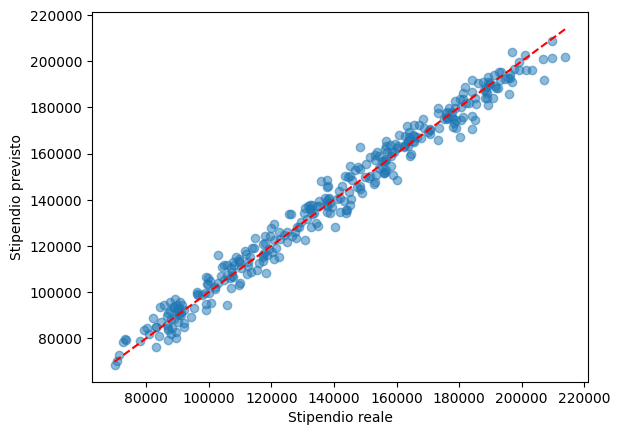

In [9]:
#valutazione del modello

model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor)

y_pred_dollars = y_scaled.inverse_transform(y_pred.cpu().numpy())
y_test_dollars = y_scaled.inverse_transform(y_test_tensor.cpu().numpy())

#calcolo dell'errore:
mae = mean_absolute_error(y_test_dollars, y_pred_dollars)
mse = mean_squared_error(y_test_dollars, y_pred_dollars)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_dollars, y_pred_dollars)

#print
print(f"MAE: ${mae:.2f}")
print(f"MSE: ${mse:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"R^2: {r2:.4f}")

#costruisco il grafico
plt.scatter(y_test_dollars,y_pred_dollars,alpha=0.5)
plt.xlabel("Stipendio reale")
plt.ylabel("Stipendio previsto")

plt.plot([y_test_dollars.min(), y_test_dollars.max()],
         [y_test_dollars.min(), y_test_dollars.max()],
         "r--")